# Getting Started with monod's Rust Extension

monod ships an optional compiled Rust extension (`monod_core`) that accelerates
three parts of the inference pipeline:

| Component | What it accelerates | Speed-up |
|---|---|---|
| **PSS evaluation** | Parallel FFT-based steady-state computation (rayon) | ~5–6× per grid point |
| **Data extraction** | Unique-histogram building from count matrices | ~10× |
| **L-BFGS-B optimizer** | Full optimisation loop in Rust — no Python callbacks | ~10–20× over serial scipy at 50–1000 genes |

The first two are **automatic** — once `monod_core` is installed every call to
`CMEModel.eval_model_pss` and `extract_data` uses the fast path with no code changes.
The Rust optimizer is the default whenever the extension is installed (`use_rust_lbfgsb="auto"`); this notebook sets the flag explicitly on both sides to make the comparison plain.

This notebook checks that the extension is active, then runs the pipeline with
and without it on the same genes.  Install the extension with `pip install monod-core`;
to build it from source see `docs/installation.md`.

## 1  Checking the installation

`monod_core` ships as a prebuilt wheel (`pip install monod-core`) for Linux x86_64
and Apple-silicon macOS.  On other platforms, or to work on the extension, build
it from source as described in `docs/installation.md`.  The next cell reports
whether it is importable and which toolchain, if any, is on the path.


In [1]:
# Work from the repository root (data in example_h5ad/, figures in figures/)
# and import monod from src/ when running against a checkout.
import os, sys
_root = os.getcwd()
while not os.path.exists(os.path.join(_root, 'setup.cfg')) and os.path.dirname(_root) != _root:
    _root = os.path.dirname(_root)
os.chdir(_root)
if os.path.isdir(os.path.join(_root, 'src')) and os.path.join(_root, 'src') not in sys.path:
    sys.path.insert(0, os.path.join(_root, 'src'))


In [2]:
import importlib, subprocess, sys, os, pathlib
os.makedirs('figures', exist_ok=True)

def _try_run(*args):
    env = os.environ.copy()
    extra = [str(pathlib.Path.home() / ".cargo" / "bin"),
             str(pathlib.Path(sys.prefix) / "bin")]
    env["PATH"] = os.pathsep.join(extra) + os.pathsep + env.get("PATH", "")
    try:
        return subprocess.check_output(list(args), stderr=subprocess.DEVNULL,
                                       text=True, env=env).strip()
    except (FileNotFoundError, subprocess.CalledProcessError):
        return None


def check_rust_setup():
    spec = importlib.util.find_spec("monod_core")
    if spec is None:
        print("monod_core NOT found — Rust acceleration is disabled.")
        print()
        print("Build it with:")
        print("  cd monod_core && maturin develop --release")
        print()
        print("Then restart the kernel and re-run this cell.")
        return False

    import monod_core as _mc
    print(f"monod_core  : {_mc.__file__}")

    rustc   = _try_run("rustc", "--version")
    maturin = _try_run("maturin", "--version")
    print(f"rustc       : {rustc}"   if rustc   else "rustc       : not found (add ~/.cargo/bin to PATH to rebuild)")
    print(f"maturin     : {maturin}" if maturin else "maturin     : not found (pip install maturin to rebuild)")

    # Check which optional features were compiled in
    has_h5ad = hasattr(_mc, 'searchdata_from_h5ad')
    print(f"h5ad reader : {'enabled  (ruanndata feature)' if has_h5ad else 'disabled (built with --no-default-features)'}")
    print()
    print("Rust extension is ready.")
    return True


rust_ready = check_rust_setup()

monod_core  : /home/coakes/miniconda3/envs/monod/lib/python3.11/site-packages/monod_core/__init__.py
rustc       : rustc 1.98.1 (48a229cea 2026-09-01)
maturin     : maturin 1.15.0
h5ad reader : enabled  (ruanndata feature)

Rust extension is ready.


## 2  Imports and data

In [3]:
import sys, os, time, warnings
import numpy as np
import scipy.sparse
import matplotlib.pyplot as plt
import anndata as ad

warnings.filterwarnings('ignore')


from monod.cme_toolbox import CMEModel, _HAS_RUST
from monod.extract_data import extract_data
from monod.inference import InferenceParameters, searchdata_from_adata
import monod_core as _mc

print(f"Rust extension loaded : {_HAS_RUST}")
print(f"monod_core version    : {getattr(_mc, '__version__', 'n/a')}")

Rust extension loaded : True
monod_core version    : n/a


In [4]:
# Load a small PBMC 10k dataset (spliced + unspliced counts)
H5AD_PATH = 'example_h5ad/processed_pbmc_10k_raw.h5ad'
adata_raw = ad.read_h5ad(H5AD_PATH)

# Select 50 genes expressed in ≥10 cells
s_mat = adata_raw.layers['spliced']
if scipy.sparse.issparse(s_mat):
    s_mat = s_mat.toarray()
expressed = np.where((s_mat > 0).sum(0) >= 10)[0]

N_GENES = 50
GENES   = list(adata_raw.var_names[expressed[:N_GENES]])
MODEL   = CMEModel('Bursty', 'Poisson')

print(f"Dataset : {adata_raw.n_obs} cells × {adata_raw.n_vars} genes")
print(f"Using   : {N_GENES} expressed genes")

Dataset : 10997 cells × 36601 genes
Using   : 50 expressed genes


## 3  Data loading: `extract_data` + `searchdata_from_adata`

The standard monod loading path works with any AnnData object and requires no
HDF5 reader.  When `monod_core` is installed, `searchdata_from_adata` automatically
returns a Rust `SearchData` object — the same type used internally by the Rust
optimizer — so the fast paths activate with no extra steps.

In [5]:
t0 = time.perf_counter()

# Step 1: extract histograms and moments from the AnnData object
adata_ext = extract_data(
    H5AD_PATH, MODEL,
    dataset_name='intro_demo',
    modality_name_dict={'unspliced': 'unspliced', 'spliced': 'spliced'},
    n_genes=len(GENES),
    genes_to_fit=GENES,
    hist_type='unique',
    viz=False,
)

# Step 2: convert to a SearchData container
#   - when monod_core is available this returns a Rust SearchData object
#   - otherwise it returns the pure-Python SearchData dataclass (same API)
search_data = searchdata_from_adata(adata_ext)

t_load = (time.perf_counter() - t0) * 1e3
print(f"Load time : {t_load:.0f} ms")
print(f"SearchData type : {type(search_data).__module__}.{type(search_data).__qualname__}")
print(f"  {search_data.n_genes} genes,  {search_data.n_cells} cells")

Load time : 4720 ms
SearchData type : builtins.SearchData
  50 genes,  10997 cells


## 4  Rust PSS fast-path (automatic)

The Rust steady-state solver activates automatically for all supported models
(`Constitutive`, `Bursty`, `CIR`, `Extrinsic`, `Delay`, `DelayedSplicing`,
`ProteinBursty`) when `monod_core` is installed.  No code changes are needed.

The cell below runs inference with scipy L-BFGS-B and the default settings to
establish a baseline.

In [6]:
# Default inference: scipy L-BFGS-B, one gene at a time.
# Other gradient_params keep their defaults (num_restarts=3, init_pattern='moments', ...).
ip_scipy = InferenceParameters(
    'intro_demo', MODEL,
    use_lengths=False,
    gradient_params={'max_iterations': 200, 'use_rust_lbfgsb': False},   # the scipy optimizer; the Rust one is the default
    gridsize=[3, 4],   # 12 sampling-rate grid points
    save=False,
)

t0 = time.perf_counter()
result_scipy = ip_scipy.fit_all_grid_points(search_data, num_cores=1, save=False)
t_scipy = time.perf_counter() - t0

result_scipy.find_sampling_optimum()
print(f"scipy (serial)  : {t_scipy:.2f} s  for {N_GENES} genes × 12 grid points")
print(f"Rust PSS active : {_HAS_RUST}")

Grid scan:   0%|          | 0/12 [00:00<?, ?it/s]

Grid scan:   8%|▊         | 1/12 [00:02<00:23,  2.17s/it]

Grid scan:  17%|█▋        | 2/12 [00:04<00:21,  2.13s/it]

Grid scan:  25%|██▌       | 3/12 [00:06<00:21,  2.39s/it]

Grid scan:  33%|███▎      | 4/12 [00:09<00:18,  2.35s/it]

...

Grid scan:  83%|████████▎ | 10/12 [00:19<00:03,  1.80s/it]

Grid scan:  92%|█████████▏| 11/12 [00:21<00:01,  1.78s/it]

Grid scan: 100%|██████████| 12/12 [00:22<00:00,  1.76s/it]

Grid scan: 100%|██████████| 12/12 [00:22<00:00,  1.91s/it]

scipy (serial)  : 22.96 s  for 50 genes × 12 grid points
Rust PSS active : True


## 5  Rust L-BFGS-B optimizer

With the extension installed the fit runs by default in a pure-Rust L-BFGS-B
implementation (`use_rust_lbfgsb="auto"`; `False` restores the scipy callback-based loop) (Cauchy point + subspace minimisation,
Moré–Thuente line search) that runs all genes in parallel via rayon.

Key differences from the scipy default:
- **No GIL round-trips** — the optimizer calls back into Rust PSS, not Python
- **Rayon outer parallelism** — all genes run simultaneously across CPU cores
- **`num_gene_cores=-1`** — tells the scheduler to use all available cores

In [7]:
# Rust L-BFGS-B: same defaults, two flags added.
#   use_rust_lbfgsb=True  — pure-Rust L-BFGS-B (the default, "auto", when the extension is installed)
#   num_gene_cores=-1     — parallelise across all CPU cores via rayon
ip_rust = InferenceParameters(
    'intro_demo', MODEL,
    use_lengths=False,
    gradient_params={
        'max_iterations' : 200,
        'num_gene_cores' : -1,
        'use_rust_lbfgsb': True,
    },
    gridsize=[3, 4],
    save=False,
)

t0 = time.perf_counter()
result_rust = ip_rust.fit_all_grid_points(search_data, num_cores=1, save=False)
t_rust = time.perf_counter() - t0

result_rust.find_sampling_optimum()
print(f"scipy (serial)      : {t_scipy:.2f} s")
print(f"Rust L-BFGS-B       : {t_rust:.2f} s")
print(f"Speedup             : {t_scipy/t_rust:.1f}×")

Grid scan:   0%|          | 0/12 [00:00<?, ?it/s]

Grid scan:   8%|▊         | 1/12 [00:00<00:02,  4.16it/s]

Grid scan:  17%|█▋        | 2/12 [00:00<00:02,  3.93it/s]

Grid scan:  25%|██▌       | 3/12 [00:01<00:03,  2.25it/s]

Grid scan:  33%|███▎      | 4/12 [00:01<00:03,  2.07it/s]

...

Grid scan:  83%|████████▎ | 10/12 [00:03<00:00,  2.91it/s]

Grid scan:  92%|█████████▏| 11/12 [00:03<00:00,  3.14it/s]

Grid scan: 100%|██████████| 12/12 [00:03<00:00,  3.34it/s]

Grid scan: 100%|██████████| 12/12 [00:03<00:00,  3.03it/s]

scipy (serial)      : 22.96 s
Rust L-BFGS-B       : 3.96 s
Speedup             : 5.8×


## 6  Parameter concordance

Both optimizers start every gene at every grid point from the same method-of-moments
estimate and converge to the same model.  The scatter below compares the inferred
biophysical parameters gene-by-gene.  Points on the diagonal indicate identical
solutions; off-diagonal points reflect cases where the two optimizers found different
local minima (see `rust_vs_python_benchmark.ipynb` for a detailed analysis).

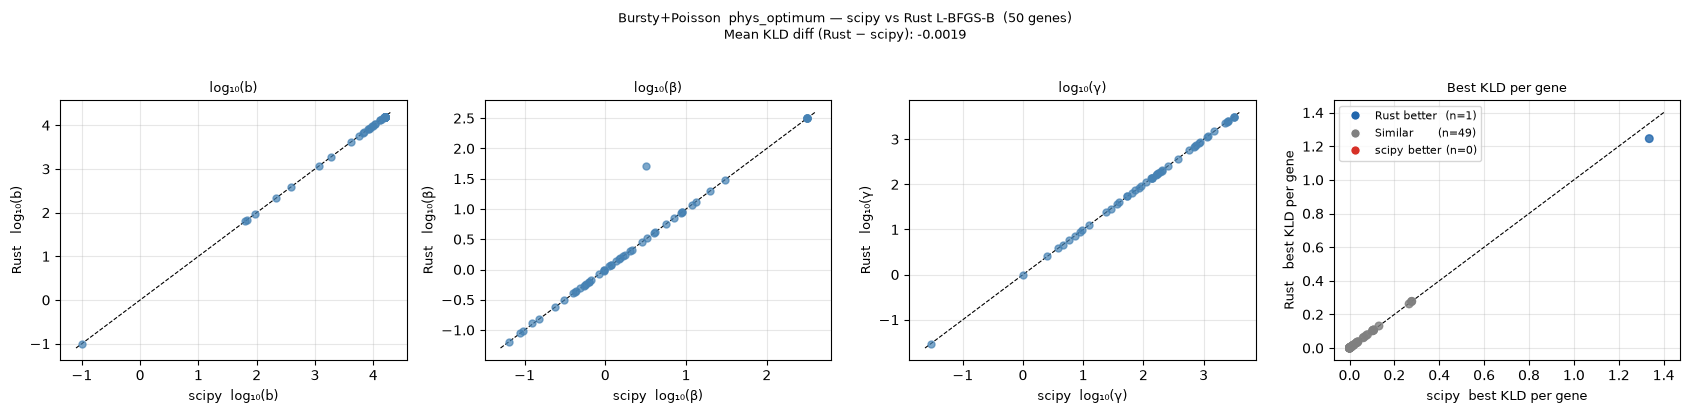

Rust better: 1  |  similar: 49  |  scipy better: 0
Mean KLD diff (Rust − scipy): -0.0019  (negative = Rust advantage)


In [8]:
p_sc = result_scipy.phys_optimum   # (n_genes, 3)  log10 [b, beta, gamma]
p_ru = result_rust.phys_optimum

k_sc = result_scipy.klds.min(axis=0)   # best KLD per gene across grid points
k_ru = result_rust.klds.min(axis=0)
kld_diff = k_ru - k_sc                 # positive = Rust worse

KLD_T = 0.01
n_better  = (kld_diff < -KLD_T).sum()
n_worse   = (kld_diff >  KLD_T).sum()
n_similar = N_GENES - n_better - n_worse

param_names = ['log₁₀(b)', 'log₁₀(β)', 'log₁₀(γ)']
C_RUST    = '#2166ac'
C_SCIPY   = '#d73027'
C_SIMILAR = 'grey'

fig, axes = plt.subplots(1, 4, figsize=(17, 4))

# ── Panels 1–3: parameter scatter ─────────────────────────────────────────────
for pi, (ax, name) in enumerate(zip(axes[:3], param_names)):
    lo = min(p_sc[:, pi].min(), p_ru[:, pi].min()) - 0.1
    hi = max(p_sc[:, pi].max(), p_ru[:, pi].max()) + 0.1
    ax.scatter(p_sc[:, pi], p_ru[:, pi], s=25, alpha=0.7, color='steelblue', zorder=3)
    ax.plot([lo, hi], [lo, hi], 'k--', lw=0.8)
    ax.set_xlabel(f'scipy  {name}', fontsize=9)
    ax.set_ylabel(f'Rust   {name}', fontsize=9)
    ax.set_title(name, fontsize=9)
    ax.grid(True, alpha=0.3)

# ── Panel 4: KLD scatter ───────────────────────────────────────────────────────
ax = axes[3]
colors = [C_RUST if d < -KLD_T else (C_SCIPY if d > KLD_T else C_SIMILAR)
          for d in kld_diff]
ax.scatter(k_sc, k_ru, c=colors, s=30, alpha=0.8, zorder=3)
lo = min(k_sc.min(), k_ru.min()) * 0.95
hi = max(k_sc.max(), k_ru.max()) * 1.05
ax.plot([lo, hi], [lo, hi], 'k--', lw=0.8)
ax.set_xlabel('scipy  best KLD per gene', fontsize=9)
ax.set_ylabel('Rust   best KLD per gene', fontsize=9)
ax.set_title('Best KLD per gene', fontsize=9)
ax.grid(True, alpha=0.3)

from matplotlib.lines import Line2D
ax.legend(handles=[
    Line2D([0],[0], marker='o', color='w', markerfacecolor=C_RUST,    ms=7, label=f'Rust better  (n={n_better})'),
    Line2D([0],[0], marker='o', color='w', markerfacecolor=C_SIMILAR, ms=7, label=f'Similar      (n={n_similar})'),
    Line2D([0],[0], marker='o', color='w', markerfacecolor=C_SCIPY,   ms=7, label=f'scipy better (n={n_worse})'),
], fontsize=8)

plt.suptitle(
    f'Bursty+Poisson  phys_optimum — scipy vs Rust L-BFGS-B  ({N_GENES} genes)\n'
    f'Mean KLD diff (Rust − scipy): {kld_diff.mean():.4f}',
    fontsize=9, y=1.02,
)
plt.tight_layout()
plt.savefig('figures/intro_rust_concordance.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Rust better: {n_better}  |  similar: {n_similar}  |  scipy better: {n_worse}')
print(f'Mean KLD diff (Rust − scipy): {kld_diff.mean():.4f}  (negative = Rust advantage)')

## 7  Optional: skipping Python AnnData with `ruanndata`

If you have the `ruanndata` feature enabled (the default build), the function
`searchdata_from_h5ad` reads an `.h5ad` file, filters genes, and builds the
`SearchData` object entirely in Rust — no Python AnnData round-trip, no GIL
overhead:

```python
import monod_core as _mc

search_data = _mc.searchdata_from_h5ad(
    'path/to/data.h5ad',
    layer_names=['unspliced', 'spliced'],
    gene_names=my_gene_list,   # optional filter
)
```

This is the fastest possible loading path and is used in `rust_vs_python_benchmark.ipynb`
for the end-to-end benchmarks.  However, it requires that `monod_core` was built
with the `ruanndata` feature (i.e. **not** `--no-default-features`) and that HDF5
is available on your system.

For portability — or if HDF5 is unavailable — the `extract_data` +
`searchdata_from_adata` path shown above gives identical inference results with
only a modest loading overhead.